# Part 1：
# K-means 聚类算法实现

## 介绍

在本练习中，你将实现 K-means 聚类算法，并将其应用于图像压缩。

In [1]:
# 用于处理目录路径
import os

# Python 的科学计算和向量计算
import numpy as np


# 绘图库
from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D
import matplotlib as mpl

from IPython.display import HTML, display, clear_output

try:
    pyplot.rcParams["animation.html"] = "jshtml"
except ValueError:
    pyplot.rcParams["animation.html"] = "html5"

# scipy 的优化模块
from scipy import optimize

# 用于加载 MATLAB mat 数据文件格式
from scipy.io import loadmat

# 本练习提供的工具库，包含作业提交等功能
import utils
from utils import check

# 告诉 matplotlib 在 notebook 内嵌显示图像
%matplotlib inline

## 1 K-means 聚类

在本练习中，你将实现 K-means 算法并将其用于图像压缩。你将首先在一个二维数据集上进行实验，以帮助你理解 K-means 算法的工作原理。之后，你将用 K-means 算法通过减少图像中出现的颜色数量来实现图像压缩，仅保留最常见的颜色。

### 1.1 实现 K-means

K-means 算法是一种自动将相似数据样本聚类的方法。具体来说，给定一个训练集 $\{x^{(1)} , \cdots, x^{(m)}\}$（其中 $x^{(i)} \in \mathbb{R}^n$），你需要将数据分成若干个紧密的“簇”。K-means 的直观思想是一个迭代过程，首先猜测初始质心，然后通过不断将样本分配到最近的质心并根据分配结果重新计算质心来优化这个猜测。

K-means 算法如下：

```python
centroids = kMeansInitCentroids(X, K)
for i in range(iterations):
    # 聚类分配步骤：将每个数据点分配到最近的质心。idx[i] 对应于 cˆ(i)，即第 i 个样本分配到的质心编号
    idx = findClosestCentroids(X, centroids)
    
    # 移动质心步骤：根据分配结果计算新的质心均值
    centroids = computeMeans(X, idx, K)
```

算法的内循环不断执行两个步骤：（1）将每个训练样本 $x^{(i)}$ 分配到最近的质心；（2）用分配到每个质心的点重新计算质心的均值。K-means 算法总会收敛到一组最终的质心均值。注意，收敛的解未必是最优的，结果依赖于初始质心的设置。因此，实际中通常会多次随机初始化 K-means，然后选择代价函数（失真）最小的结果。你将在接下来的部分分别实现 K-means 算法的两个阶段。

#### 1.1.1 寻找最近的质心

在 K-means 算法的“聚类分配”阶段，算法会根据当前质心的位置，将每个训练样本 $x^{(i)}$ 分配到最近的质心。具体来说，对于每个样本 $i$，我们设置

$$c^{(i)} := j \quad \text{使得} \quad \lvert\rvert x^{(i)} - \mu_j  \lvert\rvert^2 最小,$$

其中 $c^{(i)}$ 是距离 $x^{(i)}$ 最近的质心的编号，$\mu_j$ 是第 $j$ 个质心的位置。注意，$c^{(i)}$ 在起始代码中对应 `idx[i]`。

你的任务是完成 `findClosestCentroids` 函数。该函数接收数据矩阵 `X` 和所有质心的位置 `centroids`，输出一个一维数组 `idx`，其中保存了每个训练样本最近的质心编号（取值范围为 $\{1, ..., K\}$，$K$ 是质心总数）。

你可以通过遍历每个训练样本和每个质心来实现。

In [2]:
def findClosestCentroids(X, centroids):
    """
    计算每个样本所属的最近质心。

    参数
    ----------
    X : array_like
        数据集，大小为 (m, n)，每一行是一个样本。
        即共有 m 个样本，每个样本 n 维。

    centroids : array_like
        K-means 的质心，大小为 (K, n)。K 是聚类数，n 是数据维度。

    返回
    -------
    idx : array_like
        一个大小为 (m, ) 的向量，保存了每个样本分配到的质心编号
        （即 X 中每一行对应的质心编号）。

    实现说明
    ------------
    遍历每个样本，找到其最近的质心，并将质心编号存入 idx 的相应位置。
    具体来说，idx[i] 应该包含第 i 个样本最近的质心的编号，
    取值范围为 0 到 K-1。

    注意
    ----
    你可以用一个 for 循环遍历所有样本来实现本函数。
    """
    # 设置 K
    K = centroids.shape[0]

    # 你需要返回以下变量
    idx = np.zeros(X.shape[0], dtype=int)

    # ====================== 在此处填写你的代码 ======================
    for i in range(X.shape[0]):
        min_dist = float('inf')
        for j in range(K):
            dist = np.linalg.norm(X[i] - centroids[j])
            if dist < min_dist:
                min_dist = dist
                idx[i] = j
    

    # =============================================================
    return idx

一旦你完成了 `findClosestCentroids` 的代码，下面的单元将运行你的代码，你应该会看到输出 `[0 2 1]`，对应于前三个样本的质心分配结果。

In [3]:
# 加载我们将要使用的示例数据集
data = loadmat(os.path.join('Data', 'ex7data2.mat'))
X = data['X']

# 选择一组初始质心
K = 3   # 3 个质心
initial_centroids = np.array([[3, 3], [6, 2], [8, 5]])

# 使用初始质心查找每个样本最近的质心
idx = findClosestCentroids(X, initial_centroids)

# 读取idx文件
idx_gt = np.load(os.path.join('Data', 'idx.npy'))

print('前5个样本最近的质心编号为:')
print(idx[:5])
print('前5个样本的正确质心编号为:')
print(idx_gt[:5])

# 检查你的实现是否正确
check('findClosestCentroids', idx, idx_gt)

前5个样本最近的质心编号为:
[0 2 1 0 0]
前5个样本的正确质心编号为:
[0 2 1 0 0]
Your answer for findClosestCentroids is correct.


In [4]:
# 查看第一个样本与所有质心的差值
X[0,:] - initial_centroids

array([[-1.15792047,  1.6075716 ],
       [-4.15792047,  2.6075716 ],
       [-6.15792047, -0.3924284 ]])

### 1.1.2 计算质心均值

在每个样本都分配到某个质心后，算法的第二阶段会为每个质心重新计算分配给它的所有点的均值。具体来说，对于每个质心 $k$，我们设置

$$ \mu_k := \frac{1}{\left| C_k\right|} \sum_{i \in C_k} x^{(i)}$$

其中 $C_k$ 是分配到质心 $k$ 的样本集合。例如，如果 $x^{(3)}$ 和 $x^{(5)}$ 都被分配到质心 $k=2$，那么你应该更新 $\mu_2 = \frac{1}{2} \left( x^{(3)} + x^{(5)} \right)$。

现在你需要完成 `computeCentroids` 函数的代码。你可以用一个循环遍历所有质心来实现该函数。你也可以用循环遍历所有样本；但如果你能用向量化实现（不使用循环），代码会更快。

In [5]:
def computeCentroids(X, idx, K):
    """
    通过计算分配给每个质心的数据点的均值，返回新的质心。

    参数
    ----------
    X : array_like
        数据集，每一行为一个数据点。即 (m, n) 的矩阵，共有 m 个样本，每个样本 n 维。

    idx : array_like 
        一个长度为 m 的向量，表示每个样本分配到的质心编号（范围 [0 ... K-1]）。

    K : int
        聚类的数量

    返回
    -------
    centroids : array_like
        (K, n) 的矩阵，每一行是分配给该质心的数据点的均值。

    实现提示
    ------------
    遍历每个质心，计算所有属于该质心的数据点的均值。具体来说，centroids[i, :] 应包含分配到第 i 个簇的数据点的均值。

    注意
    -----
    你可以用一个循环遍历所有质心来实现。
    """
    # 有用的变量
    m, n = X.shape
    # 你需要正确返回以下变量
    centroids = np.zeros((K, n))

    # ====================== 在此处填写你的代码 ======================
    for i in range(K):
        points = X[idx == i]
        if len(points) > 0:
            centroids[i] = np.mean(points, axis=0)

    
    # =============================================================
    return centroids

完成 `computeCentroids` 的代码后，下面的单元会运行你的代码，并输出 K-means 第一步后的质心结果。

In [6]:
# 根据上一步找到的最近质心，计算均值
centroids = computeCentroids(X, idx, K)


# 读取centroids文件
centroids_gt = np.load(os.path.join('Data', 'centroids.npy'))

print('初始分配后计算得到的质心为:')
print(centroids)
print('\n质心应为')
print('   [ 2.428301 3.157924 ]')
print('   [ 5.813503 2.633656 ]')
print('   [ 7.119387 3.616684 ]')

# 检查你的实现是否正确
check('computeCentroids', centroids, centroids_gt)

初始分配后计算得到的质心为:
[[2.42830111 3.15792418]
 [5.81350331 2.63365645]
 [7.11938687 3.6166844 ]]

质心应为
   [ 2.428301 3.157924 ]
   [ 5.813503 2.633656 ]
   [ 7.119387 3.616684 ]
Your answer for computeCentroids is correct.


### 1.2 K-means 算法在示例数据集上的应用

完成前面两个函数（`findClosestCentroids` 和 `computeCentroids`）后，你就可以运行完整的 K-means 算法了。下面的单元会在一个二维玩具数据集上运行 K-means 算法，帮助你理解 K-means 的工作过程。你的函数会在 `utils.py` 的 `runKmeans` 函数中被调用。建议你阅读该函数，理解其工作原理。注意，代码会在循环中多次调用你实现的两个函数。

运行下一个单元时，K-means 代码会生成一个动画，逐步展示算法每次迭代的进展。最后，你的图像应该与下方所示类似。

![](Figures/kmeans_result.png)

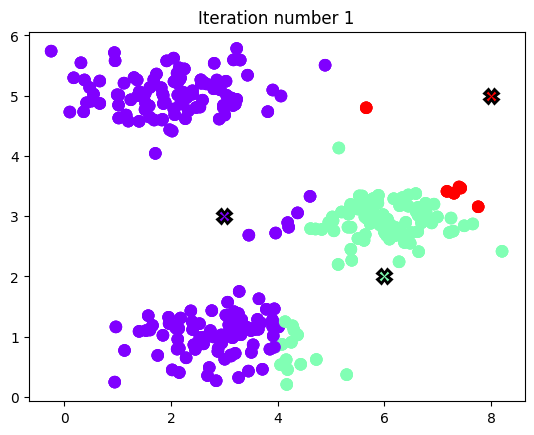

In [7]:
# 加载示例数据集
data = loadmat(os.path.join('Data', 'ex7data2.mat'))

# 设置 K-means 的参数
K = 3
max_iters = 10

# 为了结果一致，这里我们指定初始质心
# 实际应用中你可以用随机样本初始化（见 kMeansInitCentroids）
initial_centroids = np.array([[3, 3], [6, 2], [8, 5]])

# 运行 K-means 算法。最后一个参数 True 表示绘制算法进展动画
centroids, idx, anim = utils.runkMeans(X, initial_centroids,
                                       findClosestCentroids, computeCentroids, max_iters, True)
anim

### 1.3 随机初始化

前面单元中示例数据集的初始质心是特意设置的，这样你能看到和上图一样的结果。实际应用中，初始化质心的一个好方法是从训练集中随机选择样本。

在本部分，你需要完成 `kMeansInitCentroids` 函数，代码如下：

```python
# 随机初始化质心

# 随机打乱样本索引
randidx = np.random.permutation(X.shape[0])
# 取前 K 个样本作为质心
centroids = X[randidx[:K], :]
```

上述代码首先随机打乱样本索引，然后根据打乱后的索引选择前 $K$ 个样本作为初始质心。这样可以避免重复选择同一个样本。

*本部分无需提交作业*

In [8]:
def kMeansInitCentroids(X, K):
    """
    该函数用于在数据集 X 上为 K-means 算法初始化 K 个质心。

    参数
    ----------
    X : array_like 
        数据集，大小为 (m x n)。

    K : int
        聚类的数量。

    返回
    -------
    centroids : array_like
        聚类的质心，是一个 (K x n) 的矩阵。

    实现说明
    ------------
    你应该将 centroids 设置为从数据集 X 中随机选择的样本。
    """
    m, n = X.shape
    
    # 你需要正确返回该变量
    centroids = np.zeros((K, n))

    # ====================== 在此处填写你的代码 ======================
    randidx = np.random.permutation(m)
    centroids = X[randidx[:K], :]    

    
    
    # =============================================================
    return centroids

### 1.4 用 K-means 进行图像压缩

在本部分，你将把 K-means 算法应用于图像压缩。我们将使用下图作为示例（图片由 Frank Wouters 授权本课程使用）。

![](Data/bird_small.png)

在常见的 24 位彩色图像表示中，每个像素由三个 8 位无符号整数（取值范围 0 到 255）表示，分别对应红、绿、蓝三种颜色的强度，这种编码方式通常称为 RGB 编码。我们的图片包含成千上万种颜色，在本部分练习中，你将把颜色数量减少到 16 种。

通过这种方式，可以高效地表示（压缩）图片。具体来说，你只需存储 16 种选定颜色的 RGB 值，并且每个像素只需存储其对应颜色的索引（4 位即可表示 16 种可能）。

在本练习中，你将使用 K-means 算法选出用于压缩图像的 16 种颜色。具体做法是将原始图像的每个像素视为一个数据样本，在 3 维 RGB 空间中用 K-means 聚类，找到最能代表像素分布的 16 个颜色。计算出聚类中心后，用这 16 种颜色替换原图像中的像素。

#### 1.4.1 对像素应用 K-means

在 Python 中，可以这样读取图片：

```python
# 读取 128x128 彩色图片（bird_small.png）
img = mpl.image.imread(os.path.join('Data', 'bird_small.png'))
```

这会生成一个三维矩阵 `A`，前两个索引表示像素位置，最后一个索引表示红、绿或蓝。例如，A[50, 33, 2] 表示第 51 行第 34 列像素的蓝色强度。

下面的代码单元会先加载图片，然后将其重塑为 m x 3 的像素颜色矩阵（m = 16384 = 128 x 128），并调用你的 K-means 函数。

找到代表图片的前 K = 16 种颜色后，可以用 `findClosestCentroids` 函数为每个像素分配最近的质心。这样，原始图片就可以用每个像素的质心编号来表示。注意，这样大大减少了描述图片所需的比特数。原图每个像素需要 24 位，总共 128 x 128 x 24 = 393,216 位。新表示法只需存储 16 种颜色（16 x 24 位），每个像素只需 4 位，总共 16 x 24 + 128 x 128 x 4 = 65,920 位，压缩比约为 6 倍。

最后，你可以通过仅根据质心分配重构图片，观察压缩效果。具体做法是用每个像素分配到的质心的均值替换原像素。下图展示了重构效果：

![](Figures/bird_compression.png)

虽然压缩后的图片保留了原图的大部分特征，但也出现了一些压缩伪影。

运行下方代码单元，计算图片中每个像素的质心及其分配。

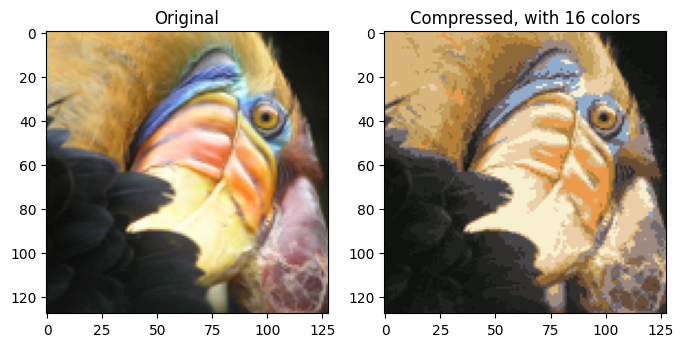

In [9]:
# ======= 可以尝试修改这些参数 ================
# 你可以尝试不同的参数取值
K = 16
max_iters = 10

# 加载一张鸟的图片
# 修改文件名和路径可以尝试你自己的图片
A = mpl.image.imread(os.path.join('Data', 'bird_small.png'))
# ==========================================================

# 除以255，使所有像素值都在0-1之间
A /= 255

# 将图片重塑为Nx3的矩阵，N为像素数。
# 每一行包含一个像素的红、绿、蓝值
# 这就是我们将用于K-means的数据集矩阵X
X = A.reshape(-1, 3)

# 使用K-means时，随机初始化质心很重要
# 请确保你已完成上面的kMeansInitCentroids函数
initial_centroids = kMeansInitCentroids(X, K)

# 运行K-means
centroids, idx = utils.runkMeans(X, initial_centroids,
                                 findClosestCentroids,
                                 computeCentroids,
                                 max_iters)

# 现在可以通过索引(idx)将每个像素映射到质心值来恢复图片
# 将恢复后的图片重塑为原始尺寸
X_recovered = centroids[idx, :].reshape(A.shape)

# 显示原始图片，乘以255还原像素值
fig, ax = pyplot.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(A*255)
ax[0].set_title('Original')
ax[0].grid(False)

# 显示压缩后的图片，同样乘以255还原像素值
ax[1].imshow(X_recovered*255)
ax[1].set_title('Compressed, with %d colors' % K)
ax[1].grid(False)